# 13 — Learning a Closure for Unresolved Physics on Two-Level Lorenz-96

Notebook [12](12_weak_constraint_4dvar_L63.ipynb) treated model error as
something to *estimate*, window by window, with an increment $\eta_t$ at
every step. This notebook treats it as something to *learn*: if the
error has structure — it is a function of the resolved state — we can fit
that function once and fold it into the model. The result is a hybrid
physics–machine-learning model, and the testbed is the classic one for
the problem, the two-level Lorenz-96 system of Wilks (2005).

## The two-level system and the closure problem

$K$ slow variables $x_k$ on a ring are each coupled to $J$ fast
variables $y_{j,k}$ that live on a finer ring of their own:

$$
\begin{aligned}
\frac{dx_k}{dt} &= (x_{k+1} - x_{k-2})\,x_{k-1} - x_k + F
                  - \underbrace{\frac{hc}{b}\sum_{j=1}^{J} y_{j,k}}_{U_k}, \\
\frac{dy_{j,k}}{dt} &= -cb\,(y_{j+2,k} - y_{j-1,k})\,y_{j+1,k} - c\,y_{j,k}
                  + \frac{hc}{b}\, x_k .
\end{aligned}
$$

The fast variables form a single cyclic chain around the whole ring,
$y_{J+1,k} = y_{1,k+1}$ (Lorenz 1996), so a fast wave can travel from one
slow sector into the next; the code keeps them as one flat vector for
that reason, and the coupling sums each sector's $J$ entries. They
evolve $c$ times faster and are $b$ times smaller, and stand in for
everything a model of the slow variables does not resolve (convection,
sub-grid turbulence, cloud microphysics). Chapter
[19](../19_physical_models.md) introduces the system; here we use
Wilks' parameters $K = 8$, $J = 32$, $F = 20$, $h = 1$, $b = c = 10$.

A model that carries only $x$ has to replace the coupling term $U_k$ by
something computable from $x$ alone. That replacement is the
**closure**, or parameterisation, $\hat U_\theta(x_k)$, and the single-level
hybrid model is

$$
\frac{dx_k}{dt} = (x_{k+1} - x_{k-2})\,x_{k-1} - x_k + F - \hat U_\theta(x_k) .
$$

Two modelling choices are baked into that form. *Locality*: the closure
at site $k$ sees only $x_k$ (one could feed it neighbours too). *Weight
sharing*: the same $\theta$ serves every site, which is the
translation invariance of the ring expressed as an inductive bias, and
in the code below is a `jax.vmap` over sites.

## What the best deterministic closure is

If we measure closure quality by mean-squared tendency error, the
optimal function of $x_k$ is the conditional expectation

$$
U^\star(x) = \mathbb{E}\big[\,U_k \mid x_k = x\,\big],
$$

and no deterministic local closure can do better than its residual
variance $\mathbb{V}[U_k \mid x_k]$. That residual is *irreducible
model error* for this model class, and it is exactly the additive
error that weak-constraint 4DVar estimates as $\eta_t$: what a
stochastic parameterisation (Wilks 2005) adds as noise, notebook 12
infers from data, and the model-error covariance $Q$ should be sized to.
The two notebooks are two halves of one picture — learn the mean of the
error, estimate the rest.

## Offline versus online learning

There are two natural objectives for $\theta$, and they are not the
same problem.

- **Offline** (tendency matching). From a simulation of the full
  system, record pairs $(x_k, U_k)$ and regress:
  $\theta^{\text{off}} = \arg\min_\theta \sum \|U_k - \hat U_\theta(x_k)\|^2$.
  This is ordinary supervised learning, cheap and convex for a linear
  parameterisation, and it targets $U^\star$ directly.
- **Online** (trajectory matching). Roll the hybrid model out from a
  true state and compare trajectories:
  $\theta^{\text{on}} = \arg\min_\theta \sum_{\text{windows}} \sum_{t \le \tau}
  \|\varphi^\theta_t(x_0) - x_t\|^2$.
  This needs gradients through the ODE solve — the
  [`DynTrajectory`](xref:api#vardax.DynTrajectory) machinery of notebook
  [09](09_param_estimation_L63.ipynb), with $\theta$ now a neural network's
  weights threaded through `diffrax` as `args`.

The offline objective is blind to how tendency errors *accumulate*: a
closure with small tendency error can still produce a model whose
trajectories drift or blow up, because errors that are individually
small can be systematically reinforced by the dynamics (the
offline-good, online-bad failure documented by Brenowitz & Bretherton
2018 and Rasp 2020 for atmospheric parameterisations). The online
objective sees the accumulated error, and also sees the time
discretisation the closure will be used with. Its cost is that the
horizon $\tau$ must stay well inside the predictability time: beyond
it, the loss surface becomes rough and the gradients through the
rollout grow exponentially with the Lyapunov exponent, the same
limitation notebook 09 met when choosing its window length.

## Where the pieces live

The full two-level system is a plain `diffrax` right-hand side; the
hybrid model is another, with the closure as its `args`; `DynTrajectory`
wraps either for rollouts, losses, and — through `as_forward_model` —
for use as the forward model of [`StrongFourDVar`](xref:api#vardax.StrongFourDVar) in
the last section, where the learned closure is used inside 4DVar.

In [1]:
import diffrax as dfx
import equinox as eqx
import jax
import jax.numpy as jnp
import lineax as lx
import matplotlib.pyplot as plt
import numpy as np
import optax

from vardax import Batch1D, DynTrajectory, MaskedIdentity, SoftBoundedForward, StrongFourDVar

## 1. The full system

We integrate the coupled system with an adaptive solver (the fast
variables need small steps), save the slow variables every
$\Delta t = 0.005$, and record the coupling term $U_k$ alongside — it is
the regression target for the offline closure, and the quantity a
closure is supposed to reproduce.

6000 saved slow states over 30 time units; x std 5.05, coupling std 4.62


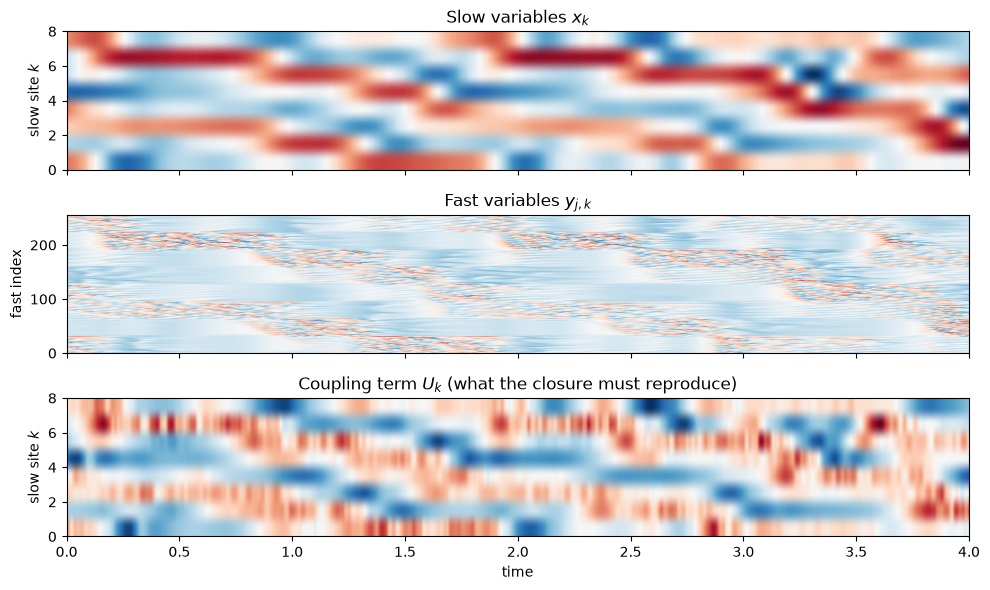

In [2]:
K, J = 8, 32
F, H_COUP, B, C = 20.0, 1.0, 10.0, 10.0
DT = 0.005


def two_level_rhs(t, s, args):
    x, y = s[:K], s[K:]
    coupling = (H_COUP * C / B) * y.reshape(K, J).sum(axis=1)
    dx = (jnp.roll(x, -1) - jnp.roll(x, 2)) * jnp.roll(x, 1) - x + F - coupling
    dy = -C * B * jnp.roll(y, -1) * (jnp.roll(y, -2) - jnp.roll(y, 1)) - C * y + (H_COUP * C / B) * jnp.repeat(x, J)
    return jnp.concatenate([dx, dy])


def coupling_term(y):
    return (H_COUP * C / B) * y.reshape(-1, K, J).sum(axis=-1)


k_x, k_y = jax.random.split(jax.random.PRNGKey(0))
s0 = jnp.concatenate([F + jax.random.normal(k_x, (K,)), 0.1 * jax.random.normal(k_y, (K * J,))])
T_END, T_BURN = 40.0, 10.0
save_ts = jnp.arange(0.0, T_END, DT)
sol = dfx.diffeqsolve(
    dfx.ODETerm(two_level_rhs), dfx.Tsit5(), 0.0, T_END, 1e-3, s0,
    saveat=dfx.SaveAt(ts=save_ts),
    stepsize_controller=dfx.PIDController(rtol=1e-5, atol=1e-5),
    max_steps=200_000,
)
keep = save_ts >= T_BURN
x_full, y_full = sol.ys[keep, :K], sol.ys[keep, K:]
U_full = coupling_term(y_full)  # (n_t, K)
n_t = x_full.shape[0]
n_train = int(0.8 * n_t)  # everything after this index is held out
print(f"{n_t} saved slow states over {n_t * DT:.0f} time units; x std {float(jnp.std(x_full)):.2f}, coupling std {float(jnp.std(U_full)):.2f}")

fig, axes = plt.subplots(3, 1, figsize=(10, 6), sharex=True)
extent = [0.0, 4.0, 0, K]
axes[0].imshow(x_full[:800].T, aspect="auto", extent=extent, cmap="RdBu_r", origin="lower")
axes[0].set_ylabel("slow site $k$")
axes[0].set_title("Slow variables $x_k$")
axes[1].imshow(y_full[:800].T, aspect="auto", extent=[0.0, 4.0, 0, K * J], cmap="RdBu_r", origin="lower")
axes[1].set_ylabel("fast index")
axes[1].set_title("Fast variables $y_{j,k}$")
axes[2].imshow(U_full[:800].T, aspect="auto", extent=extent, cmap="RdBu_r", origin="lower")
axes[2].set_ylabel("slow site $k$")
axes[2].set_title("Coupling term $U_k$ (what the closure must reproduce)")
axes[2].set_xlabel("time")
plt.tight_layout()
plt.show()

## 2. Offline closures: polynomial and neural

The scatter of $U_k$ against $x_k$, pooled over sites and over the
first 80 % of the simulation in time, is the whole offline dataset; the
last 20 % is held out for the forecast and assimilation experiments
below, for the offline closures as much as for the online one. It has a clear mean curve — the conditional
expectation $U^\star$ — and a wide spread around it, the irreducible
residual. We fit two closures to it:

- a quartic polynomial, as in Wilks (2005), by least squares; and
- a small MLP, one input and one output, by Adam on the same
  mean-squared error.

Both estimate $U^\star$. Neither can do anything about the spread, and
the printed residual standard deviation is the floor for any local
deterministic closure. One difference matters later: outside the range
of the data a polynomial's leading term takes over, and a quartic
closure evaluated at a state a few times larger than anything on the
attractor returns a tendency large enough to blow the model up. The
polynomial is therefore clipped to its fitting range; the MLP, with
ReLU-like units, extrapolates roughly linearly and needs no such guard.

coupling std          : 4.630
residual std, poly    : 1.790
residual std, MLP     : 1.776


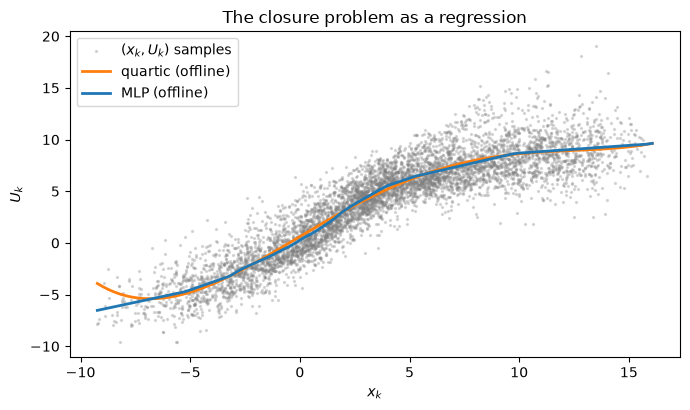

In [3]:
x_pool = x_full[:n_train].reshape(-1)
U_pool = U_full[:n_train].reshape(-1)
poly_coef = np.polyfit(np.asarray(x_pool), np.asarray(U_pool), deg=4)
X_LO, X_HI = float(x_pool.min()), float(x_pool.max())


def poly_closure(x, coef=jnp.asarray(poly_coef)):
    # A quartic's x^4 tail makes the hybrid model explode for states outside
    # the fitting range (which an optimiser's line search will try), so the
    # polynomial is only ever evaluated inside it.
    return jnp.polyval(coef, jnp.clip(x, X_LO, X_HI))


mlp_init = eqx.nn.MLP(in_size=1, out_size=1, width_size=32, depth=2, key=jax.random.PRNGKey(1))


def mlp_closure(x, mlp):
    return jax.vmap(lambda xi: mlp(xi[None])[0])(x)


def offline_loss(mlp, x, u):
    return jnp.mean((mlp_closure(x, mlp) - u) ** 2)


opt_off = optax.adam(3e-3)


@eqx.filter_jit
def offline_step(mlp, opt_state, x, u):
    loss, grads = eqx.filter_value_and_grad(offline_loss)(mlp, x, u)
    updates, opt_state = opt_off.update(grads, opt_state, mlp)
    return eqx.apply_updates(mlp, updates), opt_state, loss


mlp_off = mlp_init
opt_state = opt_off.init(eqx.filter(mlp_off, eqx.is_array))
keys = jax.random.split(jax.random.PRNGKey(2), 3000)
for k in keys:
    idx = jax.random.choice(k, x_pool.shape[0], (4096,))
    mlp_off, opt_state, loss_off = offline_step(mlp_off, opt_state, x_pool[idx], U_pool[idx])

resid_poly = U_pool - poly_closure(x_pool)
resid_mlp = U_pool - mlp_closure(x_pool, mlp_off)
print(f"coupling std          : {float(jnp.std(U_pool)):.3f}")
print(f"residual std, poly    : {float(jnp.std(resid_poly)):.3f}")
print(f"residual std, MLP     : {float(jnp.std(resid_mlp)):.3f}")

x_grid = jnp.linspace(float(x_pool.min()), float(x_pool.max()), 200)
fig, ax = plt.subplots(figsize=(7, 4.2))
sub = jax.random.choice(jax.random.PRNGKey(3), x_pool.shape[0], (6000,), replace=False)
ax.scatter(x_pool[sub], U_pool[sub], s=2, alpha=0.25, color="gray", label="$(x_k, U_k)$ samples")
ax.plot(x_grid, poly_closure(x_grid), color="tab:orange", lw=2, label="quartic (offline)")
ax.plot(x_grid, mlp_closure(x_grid, mlp_off), color="tab:blue", lw=2, label="MLP (offline)")
ax.set_xlabel("$x_k$")
ax.set_ylabel("$U_k$")
ax.set_title("The closure problem as a regression")
ax.legend()
plt.tight_layout()
plt.show()

## 3. Online learning through the solver

The offline fit had a luxury real problems never have: it saw the
coupling term $U_k$ itself. In practice the unresolved variables are
unresolved — all we have is the trajectory of the resolved state. The
online route needs nothing else. Wrap the hybrid model as a
`DynTrajectory` with a *freshly initialised* MLP as its parameters and
minimise the trajectory loss over short windows: from a true slow
state, roll the hybrid model $\tau = 10$ steps ($0.05$ time units) and
compare with the true slow trajectory. Gradients flow through `diffrax`
into the closure weights, exactly as they flowed into $(\sigma, \rho,
\beta)$ in notebook 09 — the parameter is now a network.

The windows are drawn from the same first 80 % of the simulation as the
offline pools; the forecast and assimilation experiments below use the
last 20 %, so nothing is scored on data it was trained on.

no closure  : trajectory MSE 0.0304   tendency MSE 36.501


MLP offline : trajectory MSE 0.0022   tendency MSE 3.154
MLP online  : trajectory MSE 0.0023   tendency MSE 3.190


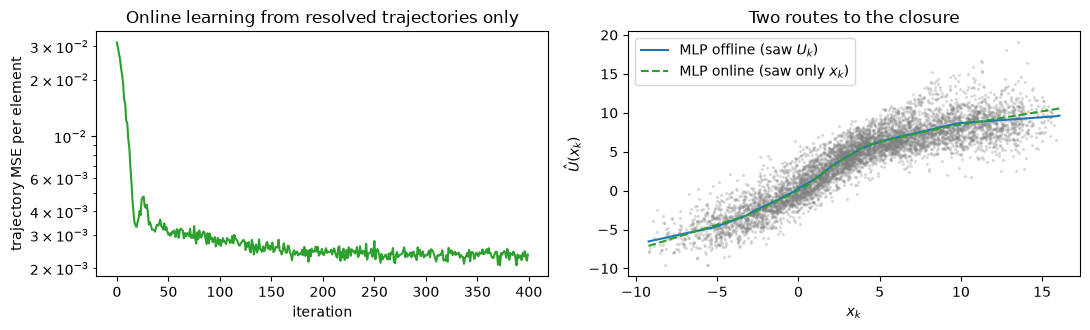

In [4]:
def l96_rhs(x):
    return (jnp.roll(x, -1) - jnp.roll(x, 2)) * jnp.roll(x, 1) - x + F


def hybrid_rhs(t, x, mlp):
    return l96_rhs(x) - mlp_closure(x, mlp)


def no_closure_rhs(t, x, args):
    return l96_rhs(x)


def poly_rhs(t, x, args):
    return l96_rhs(x) - poly_closure(x)


ode_kwargs = dict(solver=dfx.Tsit5(), stepsize=dfx.ConstantStepSize())
hybrid = DynTrajectory(model=hybrid_rhs, params=mlp_off, **ode_kwargs)
model_none = DynTrajectory(model=no_closure_rhs, **ode_kwargs)
model_poly = DynTrajectory(model=poly_rhs, **ode_kwargs)

TAU = 10
ts_win = jnp.arange(TAU + 1) * DT
starts_train = jnp.arange(0, n_train - TAU, 5)
windows_train = jax.vmap(lambda s: jax.lax.dynamic_slice_in_dim(x_full, s, TAU + 1))(starts_train)  # (n_win, TAU+1, K)


def online_loss(mlp, windows):
    def one(w):
        return hybrid.loss(w, ts_win, params=mlp)

    return jnp.mean(jax.vmap(one)(windows)) / ((TAU + 1) * K)


opt_on = optax.adam(3e-3)


@eqx.filter_jit
def online_step(mlp, opt_state, windows):
    loss, grads = eqx.filter_value_and_grad(online_loss)(mlp, windows)
    updates, opt_state = opt_on.update(grads, opt_state, mlp)
    return eqx.apply_updates(mlp, updates), opt_state, loss


mlp_on = mlp_init  # from scratch: the trajectories are the only data
opt_state = opt_on.init(eqx.filter(mlp_on, eqx.is_array))
hist_online = []
for k in jax.random.split(jax.random.PRNGKey(4), 400):
    idx = jax.random.choice(k, windows_train.shape[0], (128,), replace=False)
    mlp_on, opt_state, loss_on = online_step(mlp_on, opt_state, windows_train[idx])
    hist_online.append(float(loss_on))

for name, m in [("no closure", None), ("MLP offline", mlp_off), ("MLP online", mlp_on)]:
    traj_mse = float(jnp.mean(jax.vmap(lambda w: model_none.loss(w, ts_win))(windows_train[:256])) / ((TAU + 1) * K)) if m is None else float(online_loss(m, windows_train[:256]))
    tend_mse = float(jnp.mean(U_pool**2)) if m is None else float(offline_loss(m, x_pool, U_pool))
    print(f"{name:12s}: trajectory MSE {traj_mse:.4f}   tendency MSE {tend_mse:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].semilogy(hist_online, color="tab:green")
axes[0].set_xlabel("iteration")
axes[0].set_ylabel("trajectory MSE per element")
axes[0].set_title("Online learning from resolved trajectories only")
axes[1].scatter(x_pool[sub], U_pool[sub], s=2, alpha=0.2, color="gray")
axes[1].plot(x_grid, mlp_closure(x_grid, mlp_off), color="tab:blue", label="MLP offline (saw $U_k$)")
axes[1].plot(x_grid, mlp_closure(x_grid, mlp_on), color="tab:green", linestyle="--", label="MLP online (saw only $x_k$)")
axes[1].set_xlabel("$x_k$")
axes[1].set_ylabel("$\\hat U(x_k)$")
axes[1].set_title("Two routes to the closure")
axes[1].legend()
plt.tight_layout()
plt.show()

The two routes land on nearly the same function, and the near-agreement
is itself informative. The online loss can only identify the closure
through its integrated effect on $x$ over $\tau$ steps; if the residual
$U_k - U^\star(x_k)$ were strongly correlated in time, the trajectory
objective would prefer a closure that compensates for that memory and
would drift away from the conditional mean (its tendency MSE would rise
as its trajectory MSE fell). Here the fast variables decorrelate within
a few slow steps, the residual is close to white at this sampling, and
the best trajectory-matching closure *is* the conditional mean. When the
two routes disagree, the online one is the better model and the offline
one is the better estimate of the physics — and only the online one is
available when the unresolved variables are genuinely unobserved.

## 4. Forecast skill

The test that matters for a model is how long its forecasts stay close
to the truth. From 200 true slow states in the held-out part of the
simulation, we run each single-level model for one time unit and
average the error over initial conditions. The climatological level
$\sqrt{2}\,\sigma_x$ is the error of a forecast that has lost all
memory of its initial condition (two independent draws from the
attractor), and marks where skill ends.

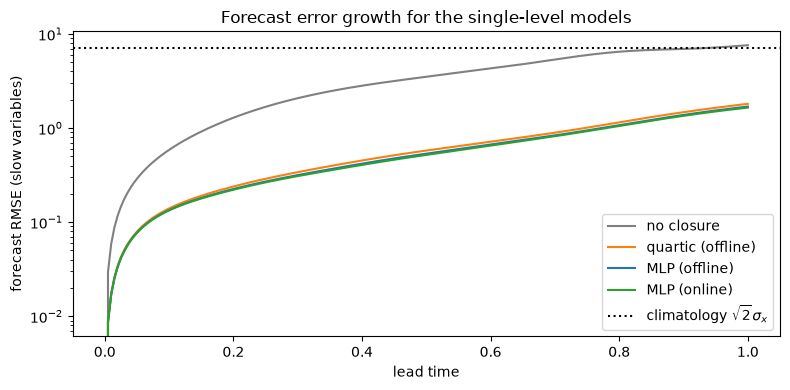

lead 0.10: no closure 0.59, quartic (offline) 0.14, MLP (offline) 0.13, MLP (online) 0.13
lead 0.25: no closure 1.68, quartic (offline) 0.29, MLP (offline) 0.27, MLP (online) 0.26
lead 0.50: no closure 3.51, quartic (offline) 0.58, MLP (offline) 0.53, MLP (online) 0.52


In [5]:
LEAD_STEPS = 200
ts_lead = jnp.arange(LEAD_STEPS + 1) * DT
starts_test = jnp.linspace(n_train, n_t - LEAD_STEPS - 1, 200).astype(int)
x0_test = x_full[starts_test]
truth_test = jax.vmap(lambda s: jax.lax.dynamic_slice_in_dim(x_full, s, LEAD_STEPS + 1))(starts_test)

models = {
    "no closure": (model_none, None),
    "quartic (offline)": (model_poly, None),
    "MLP (offline)": (hybrid, mlp_off),
    "MLP (online)": (hybrid, mlp_on),
}
skill = {}
for name, (m, p) in models.items():
    fc = jax.vmap(lambda x0: m(x0, ts_lead, params=p))(x0_test)
    skill[name] = jnp.sqrt(jnp.mean((fc - truth_test) ** 2, axis=(0, 2)))

clim = float(jnp.sqrt(2.0) * jnp.std(x_full))
fig, ax = plt.subplots(figsize=(8, 4))
for (name, err), color in zip(skill.items(), ["gray", "tab:orange", "tab:blue", "tab:green"]):
    ax.plot(ts_lead, err, color=color, label=name)
ax.axhline(clim, color="black", linestyle=":", label=r"climatology $\sqrt{2}\sigma_x$")
ax.set_xlabel("lead time")
ax.set_ylabel("forecast RMSE (slow variables)")
ax.set_yscale("log")
ax.legend()
ax.set_title("Forecast error growth for the single-level models")
plt.tight_layout()
plt.show()

for lead in (0.1, 0.25, 0.5):
    i = int(round(lead / DT))
    print(f"lead {lead:4.2f}: " + ", ".join(f"{name} {float(err[i]):.2f}" for name, err in skill.items()))

Without a closure the model is not merely inaccurate, it is the wrong
system: its forcing is off by the mean of $U_k$ (about $\bar U$, printed
in section 2), so its error is large from the first step. The closures
remove that bias and the remaining error grows exponentially from the
residual level, as it must in a chaotic system: a closure changes the
*starting point* of the error-growth curve, not its slope, which is set
by the Lyapunov exponent of the resolved dynamics.

## 5. The learned closure inside 4DVar

A better forward model is worth more inside data assimilation than in a
free forecast, because the analysis re-anchors it to observations
every window. We now use each single-level model as the forward model
of strong-constraint 4DVar on the slow variables: windows of 20 steps
at $\Delta t = 0.02$ (0.4 time units, about two error-doubling times
for the closed models), half the sites observed at every step with
noise $\sigma_{obs} = 1$, a background with error $\sigma_b = 2$. The
comparison is the analysis error of $x_0$ and of the whole window,
averaged over 16 windows from the held-out data.

One practical detail: Lorenz-96 has quadratic terms, so a line-search
trial far outside the attractor overflows the rollout. The
[`SoftBoundedForward`](xref:api#vardax.SoftBoundedForward) adapter leaves states untouched
inside a box (the printed maximum $|x_k|$ is well inside it) and
saturates them smoothly outside, on the way into and out of every step;
a wild trial state still gets a large, finite cost and is rejected. (A
hard clip would do the same to the cost but zero the gradient, which
breaks BFGS's curvature update.)

This is the strong-constraint counterpart of notebook 12: there, the
model error was estimated as $\eta_t$; here it has been learned into
$M$, and what remains — the irreducible residual of section 2 — is what
a weak-constraint formulation with a learned closure would still have
to absorb.

max |x_k| on the attractor: 16.1
analysis error of x0 / window RMSE (background x0 error 2.45):


  no closure        : x0 1.46   window 0.95


  quartic (offline) : x0 0.58   window 0.37


  MLP (offline)     : x0 0.57   window 0.37


  MLP (online)      : x0 0.57   window 0.36


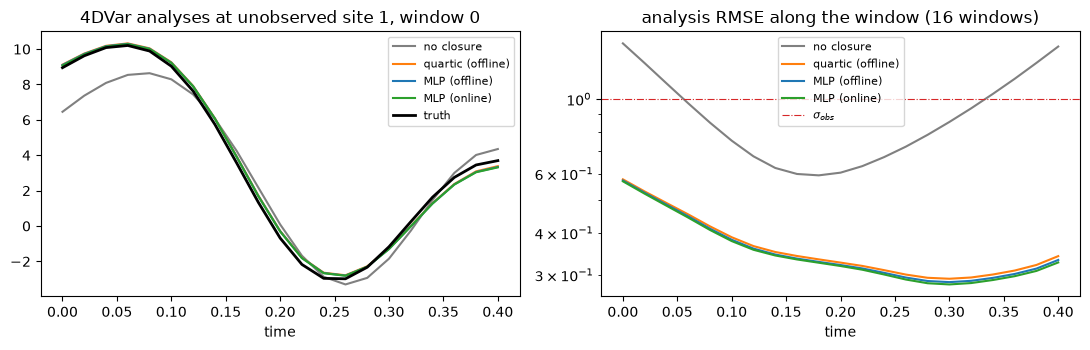

In [6]:
T_DA, DT_DA = 20, 0.02
SIGMA_OBS, SIGMA_BG = 1.0, 2.0
STRIDE = int(DT_DA / DT)
ts_da = jnp.arange(T_DA + 1) * DT_DA
starts_da = jnp.linspace(n_train, n_t - STRIDE * (T_DA + 1) - 1, 16).astype(int)
truth_da = jax.vmap(lambda s: jax.lax.dynamic_slice_in_dim(x_full, s, STRIDE * (T_DA + 1))[::STRIDE])(starts_da)  # (16, T+1, K)

k_o, k_b = jax.random.split(jax.random.PRNGKey(5))
mask_da = jnp.zeros((T_DA + 1, K)).at[:, ::2].set(1.0)
y_da = (truth_da + SIGMA_OBS * jax.random.normal(k_o, truth_da.shape)) * mask_da
xb_da = truth_da[:, 0] + SIGMA_BG * jax.random.normal(k_b, (16, K))
batch_da = Batch1D(input=y_da, mask=jnp.broadcast_to(mask_da, y_da.shape), target=truth_da)


def diag_cov(variance):
    return lx.TaggedLinearOperator(lx.DiagonalLinearOperator(jnp.full(K, variance)), lx.positive_semidefinite_tag)


def analyse(m, p, batch, xb):
    ode = DynTrajectory(model=m.model, params=p, **ode_kwargs)

    @jax.jit
    def one(b_in, b_mask, xb_i):
        # The background differs per window, so the model is rebuilt inside
        # the jitted function (one compilation, sixteen calls).
        strong = StrongFourDVar(
            forward=SoftBoundedForward(ode.as_forward_model(dt=DT_DA), bound=25.0),
            obs_op=MaskedIdentity(),
            prior_mean=xb_i,
            prior_cov_op=diag_cov(SIGMA_BG**2),
            obs_cov_op=diag_cov(SIGMA_OBS**2),
            max_steps=200,
        )
        x0 = strong(Batch1D(input=b_in[None], mask=b_mask[None]))[0]
        return ode(x0, ts_da)

    return jnp.stack([one(batch.input[i], batch.mask[i], xb[i]) for i in range(xb.shape[0])])


print(f"max |x_k| on the attractor: {float(jnp.max(jnp.abs(x_full))):.1f}")
print("analysis error of x0 / window RMSE (background x0 error "
      f"{float(jnp.sqrt(jnp.mean((xb_da - truth_da[:, 0]) ** 2))):.2f}):")
da_results = {}
for name, (m, p) in models.items():
    traj = analyse(m, p, batch_da, xb_da)
    da_results[name] = traj
    e0 = float(jnp.sqrt(jnp.mean((traj[:, 0] - truth_da[:, 0]) ** 2)))
    ew = float(jnp.sqrt(jnp.mean((traj - truth_da) ** 2)))
    print(f"  {name:18s}: x0 {e0:.2f}   window {ew:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
w = 0
site = 1  # an unobserved site
for (name, traj), color in zip(da_results.items(), ["gray", "tab:orange", "tab:blue", "tab:green"]):
    axes[0].plot(ts_da, traj[w, :, site], color=color, label=name)
axes[0].plot(ts_da, truth_da[w, :, site], color="black", lw=2, label="truth")
axes[0].set_title(f"4DVar analyses at unobserved site {site}, window 0")
axes[0].set_xlabel("time")
axes[0].legend(fontsize=8)
for (name, traj), color in zip(da_results.items(), ["gray", "tab:orange", "tab:blue", "tab:green"]):
    axes[1].plot(ts_da, jnp.sqrt(jnp.mean((traj - truth_da) ** 2, axis=(0, 2))), color=color, label=name)
axes[1].axhline(SIGMA_OBS, color="tab:red", linestyle="-.", lw=0.8, label=r"$\sigma_{obs}$")
axes[1].set_title("analysis RMSE along the window (16 windows)")
axes[1].set_xlabel("time")
axes[1].set_yscale("log")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## Summary

- The coupling to unresolved variables is a function of the resolved
  state plus a residual. The best deterministic local closure is the
  conditional mean; the residual is irreducible model error for that
  model class, and is what a stochastic parameterisation or a
  weak-constraint increment has to carry.
- Offline (tendency) and online (trajectory) objectives fit different
  things. Offline targets the physical coupling; online targets the
  best model, solver and error accumulation included, at the price of
  gradients through the ODE solve and a horizon bounded by
  predictability.
- A closure moves the starting point of the forecast-error curve, not
  its exponential slope.
- Inside 4DVar the forward model's quality sets how much the
  observations at later times can say about the state at earlier times
  and at unobserved sites; the learned closures cut the no-closure
  model's analysis error by more than half over a 0.4-time-unit window.
  The same `DynTrajectory` object serves as trainable model, forecast
  model, and 4DVar forward.

Notebook [09](09_param_estimation_L63.ipynb) is the scalar-parameter
version of the online fit; notebook [12](12_weak_constraint_4dvar_L63.ipynb)
handles the residual this notebook cannot learn.